In [3]:
import pandas as pd
import numpy as np

In [7]:
data=pd.read_csv("day_1km_perth.csv")

In [9]:
df = data.copy()
df["Date"] = pd.to_datetime(df["Date"])

# Drop the rows where the temperature is 0
df = df[df["MOD11A1_061_LST_Day_1km"] != 0]

# Drop 29 Feb so every year has at most 365 days
df = df[~((df["Date"].dt.month == 2) & (df["Date"].dt.day == 29))]

# Day number 1-365: in leap years, move days after Feb back by 1
after_feb_leap = df["Date"].dt.is_leap_year & (df["Date"].dt.month > 2)

new_df = pd.DataFrame({
    "Year": df["Date"].dt.year,
    "Day": df["Date"].dt.dayofyear - after_feb_leap.astype(int),
    "LST_K": df["MOD11A1_061_LST_Day_1km"],
}).reset_index(drop=True)

C:\Users\nadun\AppData\Local\Temp\ipykernel_17552\2733486668.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Date"] = pd.to_datetime(df["Date"])


In [11]:
new_df

,Year,Day,LST_K
0,2000,57,299.44
1,2000,58,309.12
2,2000,61,301.52
3,2000,62,302.70
4,2000,63,303.58
...,...,...,...
8823,2026,309,298.36
8824,2026,311,299.98
8825,2026,312,297.82
8826,2026,315,293.28


In [13]:
all_days = set(range(1, 366))            # check if there are missing days between 1-365
present = set(new_df["Day"].unique())

missing_days = sorted(all_days - present)
print(f"Days with no data in any year: {missing_days if missing_days else 'none'}")

Days with no data in any year: none


Which is good, which means we have some data from every day of year.

# Testing models for temperature

To decide between Linear, Quadratic or Harmonic

In [18]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error, r2_score

df = new_df.copy()
df["Yr"] = df["Year"] - 2000                      # centred year
df["sin1"] = np.sin(2 * np.pi * df["Day"] / 365)  # annual cycle
df["cos1"] = np.cos(2 * np.pi * df["Day"] / 365)
df["sin2"] = np.sin(4 * np.pi * df["Day"] / 365)  # half-year harmonic (allows a lopsided season)
df["cos2"] = np.cos(4 * np.pi * df["Day"] / 365)

# Time-based split: train on the past, test on recent years
train = df[df["Year"] <= 2021]
test  = df[df["Year"] >= 2022]

models = {
    "Linear":    "LST_K ~ Yr + Day",
    "Quadratic": "LST_K ~ Yr + I(Yr**2) + Day + I(Day**2)",
    "Harmonic":  "LST_K ~ Yr + sin1 + cos1 + sin2 + cos2",
}

results, fits = [], {}
for name, formula in models.items():
    fit = smf.ols(formula, data=train).fit()
    pred = fit.predict(test)
    fits[name] = fit
    results.append({
        "Model": name,
        "Train R²": fit.rsquared,
        "Test R²": r2_score(test["LST_K"], pred),
        "Test RMSE (K)": np.sqrt(mean_squared_error(test["LST_K"], pred)),
        "AIC": fit.aic,
        "BIC": fit.bic,
    })

print(pd.DataFrame(results).round(3))

       Model  Train R²  Test R²  Test RMSE (K)        AIC        BIC
0     Linear     0.001   -0.087          8.437  51336.409  51357.024
1  Quadratic     0.541    0.362          6.464  45795.084  45829.443
2   Harmonic     0.617    0.645          4.819  44504.213  44545.445


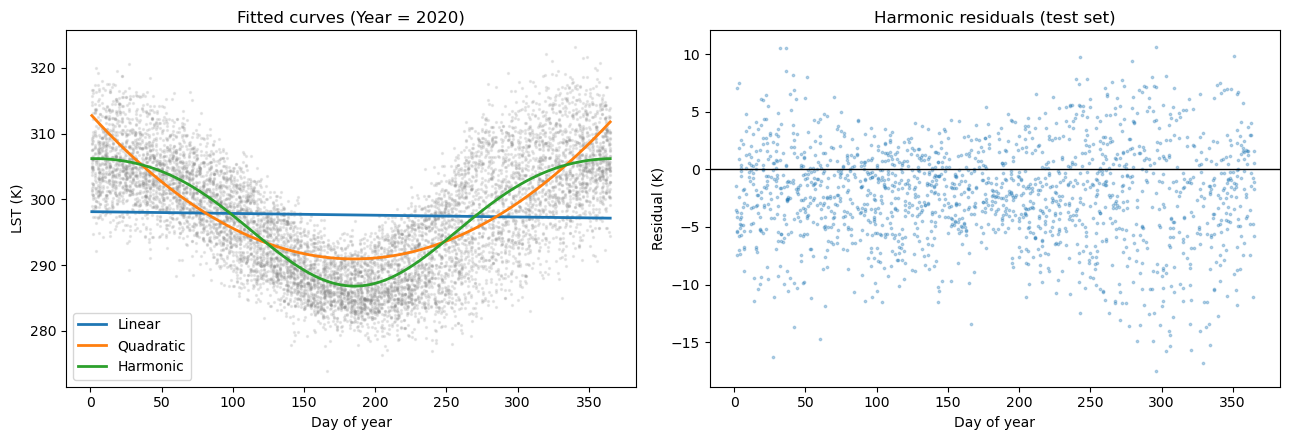

                            OLS Regression Results                            
Dep. Variable:                  LST_K   R-squared:                       0.617
Model:                            OLS   Adj. R-squared:                  0.617
Method:                 Least Squares   F-statistic:                     2297.
Date:                Sun, 15 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:50:38   Log-Likelihood:                -22246.
No. Observations:                7129   AIC:                         4.450e+04
Df Residuals:                    7123   BIC:                         4.455e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    298.1296      0.128   2337.720      0.0

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Fitted seasonal curve for one year vs the data
days = pd.DataFrame({"Day": np.arange(1, 366), "Yr": 20})
days["sin1"] = np.sin(2*np.pi*days.Day/365); days["cos1"] = np.cos(2*np.pi*days.Day/365)
days["sin2"] = np.sin(4*np.pi*days.Day/365); days["cos2"] = np.cos(4*np.pi*days.Day/365)

axes[0].scatter(df["Day"], df["LST_K"], s=2, alpha=0.15, color="grey")
for name, fit in fits.items():
    axes[0].plot(days["Day"], fit.predict(days), label=name, lw=2)
axes[0].set(xlabel="Day of year", ylabel="LST (K)", title="Fitted curves (Year = 2020)")
axes[0].legend()

# Residuals by day for the best model; a pattern here means the model misses something
best = "Harmonic"
resid = test["LST_K"] - fits[best].predict(test)
axes[1].scatter(test["Day"], resid, s=3, alpha=0.3)
axes[1].axhline(0, color="k", lw=1)
axes[1].set(xlabel="Day of year", ylabel="Residual (K)", title=f"{best} residuals (test set)")

plt.tight_layout(); plt.show()

print(fits[best].summary())   # check the Yr coefficient and its p-value

In [21]:
df

,Year,Day,LST_K,Yr,sin1,cos1,sin2,cos2
0,2000,57,299.44,0,0.831171,0.556017,0.924291,-0.381689
1,2000,58,309.12,0,0.840618,0.541628,0.910605,-0.413279
2,2000,61,301.52,0,0.867456,0.497513,0.863142,-0.504961
3,2000,62,302.70,0,0.875892,0.482508,0.845249,-0.534373
4,2000,63,303.58,0,0.884068,0.467359,0.826354,-0.563151
...,...,...,...,...,...,...,...,...
8823,2026,309,298.36,26,-0.821477,0.570242,-0.936881,-0.349647
8824,2026,311,299.98,26,-0.801361,0.598181,-0.958718,-0.284359
8825,2026,312,297.82,26,-0.790946,0.611886,-0.967938,-0.251190
8826,2026,315,293.28,26,-0.758306,0.651899,-0.988678,-0.150055


In [24]:
fit_hac = smf.ols("LST_K ~ Yr + sin1 + cos1 + sin2 + cos2", data=train).fit(
    cov_type="HAC", cov_kwds={"maxlags": 10})
print(fit_hac.summary())

                            OLS Regression Results                            
Dep. Variable:                  LST_K   R-squared:                       0.617
Model:                            OLS   Adj. R-squared:                  0.617
Method:                 Least Squares   F-statistic:                     501.5
Date:                Sun, 15 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:50:40   Log-Likelihood:                -22246.
No. Observations:                7129   AIC:                         4.450e+04
Df Residuals:                    7123   BIC:                         4.455e+04
Df Model:                           5                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    298.1296      0.368    810.270      0.0

In [28]:
Year=2027
Day=5

In [30]:
def predict_lst(year, day):
    t = 2 * np.pi * day / 365
    return (298.130 - 0.0305 * (year - 2000)
            - 0.487 * np.sin(t)   + 9.695 * np.cos(t)
            - 0.111 * np.sin(2*t) - 1.019 * np.cos(2*t))

In [32]:
predict_lst(Year,Day) - 273.15

32.75079312121733

      mean  count
Year             
2022 -2.00    305
2023 -0.12    376
2024 -1.02    359
2025 -3.20    354
2026 -4.65    305


<Axes: title={'center': 'Annual mean LST'}, xlabel='Year'>

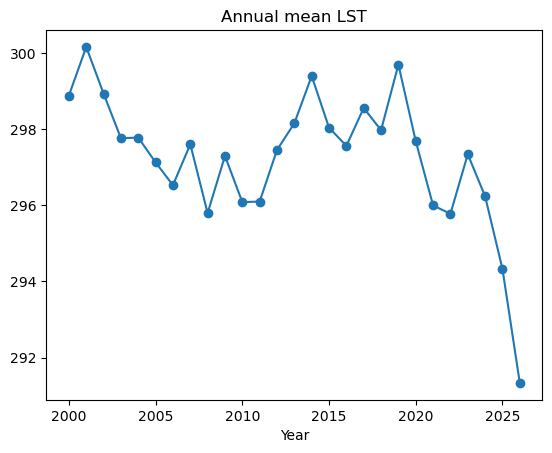

In [34]:
# 1. Bias per test year: is it stable or growing?
resid = test["LST_K"] - fits["Harmonic"].predict(test)
print(resid.groupby(test["Year"]).agg(["mean", "count"]).round(2))

# 2. Annual mean LST over the whole record: look for a step around 2020-22
new_df.groupby("Year")["LST_K"].mean().plot(marker="o", title="Annual mean LST")

Quite significantly colder readings in recent years from 2021 onwards, any satellite measuring or device error?